In [1]:
%load_ext autoreload
%autoreload 2

# 03 — Modelagem

Classificação no nível do aluno (decisão D5): cada município é expandido em alfabetizados (1) e não alfabetizados (0), com pesos iguais às contagens. Divisão treino/teste e validação cruzada no nível do município, estratificadas por UF. Desempenho reportado em relação ao teto (AUC do oráculo).

1. Dados: divisão e expansão
2. Baseline e modelos
3. Ablações
4. Avaliação final no teste

In [2]:
import numpy as np
import pandas as pd

from src.modeling import config
from src.modeling.data import carregar_base, dividir_treino_teste, expandir_alunos

pd.set_option("display.width", 160)

base = carregar_base()
features = config.selecionar_features(base.columns)
print(f"Features curadas: {len(features)}")
assert len(features) == config.N_FEATURES_ESPERADAS

for familia in config.FAMILIAS_ABLACAO:
    n = len(config.selecionar_features(base.columns, excluir_familias=[familia]))
    print(f"  sem '{familia}': {n} features")

treino, teste = dividir_treino_teste(base)
print(f"\nTreino: {len(treino):,} municípios | Teste: {len(teste):,} municípios")

contagem_uf = pd.DataFrame({
    "treino": treino["ter_uf"].value_counts(),
    "teste": teste["ter_uf"].value_counts(),
})
print(f"UFs presentes no teste: {contagem_uf['teste'].notna().sum()} de {base['ter_uf'].nunique()} da base")
print(f"Menor número de municípios de uma UF no teste: {int(contagem_uf['teste'].min())}")

X, y, pesos, grupos = expandir_alunos(treino, features)
print(f"\nExpandido (treino): {X.shape[0]:,} registros × {X.shape[1]} features")
print("Registros por município:", sorted(pd.Series(grupos).value_counts().unique()))
print("Soma dos pesos = total de alunos:", np.isclose(pesos.sum(), treino["n_alunos"].sum()))
print(f"Taxa ponderada no treino: {100 * np.average(y, weights=pesos):.2f}%")

Features curadas: 44
  sem 'fluxo': 39 features
  sem 'territorio': 42 features

Treino: 4,360 municípios | Teste: 1,090 municípios
UFs presentes no teste: 25 de 25 da base
Menor número de municípios de uma UF no teste: 3

Expandido (treino): 8,720 registros × 44 features
Registros por município: [np.int64(2)]
Soma dos pesos = total de alunos: True
Taxa ponderada no treino: 58.13%


In [3]:
from src.modeling.pipelines import construir_baseline, construir_hgb, construir_logistica

modelos = {
    "baseline": construir_baseline(),
    "logistica": construir_logistica(features),
    "hgb": construir_hgb(features),
}

for nome, modelo in modelos.items():
    modelo.fit(X, y, modelo__sample_weight=pesos)
    p = modelo.predict_proba(X)[:, 1]
    print(
        f"{nome:<10} prob. min={p.min():.3f} máx={p.max():.3f} "
        f"média ponderada={np.average(p, weights=pesos):.3f}"
    )

colunas_logistica = modelos["logistica"].named_steps["prep"].get_feature_names_out()
print(f"\nColunas após o pré-processamento da logística: {len(colunas_logistica)}")
print([c for c in colunas_logistica if "missingindicator" in c])

baseline   prob. min=0.581 máx=0.581 média ponderada=0.581
logistica  prob. min=0.220 máx=0.924 média ponderada=0.581
hgb        prob. min=0.237 máx=0.967 média ponderada=0.581

Colunas após o pré-processamento da logística: 71
['estrutural__missingindicator_ce_alunos_turma_creche', 'estrutural__missingindicator_ce_alunos_turma_multietapa']


## 2. Comparação de modelos (validação cruzada, 5 folds)

Todos os modelos com as 44 features curadas, avaliados nos municípios de validação de cada fold. Métricas no nível do aluno (ponderadas) e do município; `pct_teto` = (AUC − 0,5) / (AUC do oráculo − 0,5).

In [4]:
from src.modeling.cv import resumir, validacao_cruzada

construtores = {
    "baseline": lambda f: construir_baseline(),
    "logistica": construir_logistica,
    "hgb": construir_hgb,
}

resultados_modelos = {
    nome: validacao_cruzada(construtor, treino, features)
    for nome, construtor in construtores.items()
}
print(resumir(resultados_modelos).to_string())

                 auc_aluno         auc_teto         pct_teto         log_loss            mae_pp auc_risco_municipio
baseline   0.5000 ± 0.0000  0.6828 ± 0.0100  0.0000 ± 0.0000  0.6800 ± 0.0058  12.9280 ± 0.5429     0.5000 ± 0.0000
logistica  0.6482 ± 0.0073  0.6828 ± 0.0100  0.8111 ± 0.0113  0.6450 ± 0.0068   7.0485 ± 0.5850     0.8710 ± 0.0080
hgb        0.6498 ± 0.0081  0.6828 ± 0.0100  0.8196 ± 0.0154  0.6435 ± 0.0069   6.7455 ± 0.5800     0.8801 ± 0.0088


### Comparação pareada (mesmos folds)

Os modelos foram avaliados nos mesmos municípios em cada fold: a comparação justa é a diferença dentro de cada fold. Para AUC e % do teto, diferença positiva favorece o HGB; para log-loss e MAE, diferença negativa favorece o HGB.

In [5]:
metricas_comparadas = ["auc_aluno", "pct_teto", "log_loss", "mae_pp", "auc_risco_municipio"]
diferenca = (
    resultados_modelos["hgb"].set_index("fold")[metricas_comparadas]
    - resultados_modelos["logistica"].set_index("fold")[metricas_comparadas]
)
print("Diferença por fold (HGB − logística):")
print(diferenca.round(4).to_string())
print("\nMédia das diferenças:")
print(diferenca.mean().round(4).to_string())
print(f"\nFolds em que o HGB tem AUC maior: {(diferenca['auc_aluno'] > 0).sum()} de {len(diferenca)}")
print(f"Folds em que o HGB tem log-loss menor: {(diferenca['log_loss'] < 0).sum()} de {len(diferenca)}")

Diferença por fold (HGB − logística):
      auc_aluno  pct_teto  log_loss  mae_pp  auc_risco_municipio
fold                                                            
0        0.0008    0.0044   -0.0007 -0.3912               0.0111
1        0.0020    0.0108   -0.0026 -0.4980               0.0122
2        0.0021    0.0119   -0.0010 -0.1813               0.0108
3       -0.0005   -0.0027   -0.0005 -0.1214               0.0057
4        0.0036    0.0181   -0.0024 -0.3230               0.0054

Média das diferenças:
auc_aluno              0.0016
pct_teto               0.0085
log_loss              -0.0014
mae_pp                -0.3030
auc_risco_municipio    0.0090

Folds em que o HGB tem AUC maior: 4 de 5
Folds em que o HGB tem log-loss menor: 5 de 5


## 3. Ablações por família

Mesmos modelos, removendo famílias inteiras: fluxo escolar (limite entre contexto e histórico de desempenho) e território (efeito estadual, que mistura política e instrumento de avaliação).

In [6]:
cenarios = {
    "todas": [],
    "sem_fluxo": ["fluxo"],
    "sem_territorio": ["territorio"],
    "sem_fluxo_e_territorio": ["fluxo", "territorio"],
}

resultados_ablacao = {}
for nome_cenario, excluir in cenarios.items():
    features_cenario = config.selecionar_features(base.columns, excluir_familias=excluir)
    for nome_modelo in ["logistica", "hgb"]:
        rotulo = f"{nome_modelo} | {nome_cenario} ({len(features_cenario)})"
        resultados_ablacao[rotulo] = validacao_cruzada(construtores[nome_modelo], treino, features_cenario)

print(resumir(resultados_ablacao)[["auc_aluno", "pct_teto", "log_loss", "mae_pp", "auc_risco_municipio"]].to_string())

                                               auc_aluno         pct_teto         log_loss            mae_pp auc_risco_municipio
logistica | todas (44)                   0.6482 ± 0.0073  0.8111 ± 0.0113  0.6450 ± 0.0068   7.0485 ± 0.5850     0.8710 ± 0.0080
hgb | todas (44)                         0.6498 ± 0.0081  0.8196 ± 0.0154  0.6435 ± 0.0069   6.7455 ± 0.5800     0.8801 ± 0.0088
logistica | sem_fluxo (39)               0.6444 ± 0.0072  0.7906 ± 0.0111  0.6463 ± 0.0066   7.2666 ± 0.5603     0.8607 ± 0.0114
hgb | sem_fluxo (39)                     0.6456 ± 0.0078  0.7966 ± 0.0152  0.6457 ± 0.0071   7.2008 ± 0.6647     0.8687 ± 0.0102
logistica | sem_territorio (42)          0.6075 ± 0.0122  0.5883 ± 0.0635  0.6629 ± 0.0031  10.2802 ± 1.0013     0.7348 ± 0.0171
hgb | sem_territorio (42)                0.6241 ± 0.0097  0.6785 ± 0.0313  0.6549 ± 0.0054   9.0825 ± 0.6488     0.8048 ± 0.0158
logistica | sem_fluxo_e_territorio (37)  0.5785 ± 0.0131  0.4317 ± 0.0835  0.6711 ± 0.0020  11.49

### Conclusões: comparação e ablações

- **HGB × logística:** o HGB vence em 4/5 folds no AUC e em 5/5 na log-loss, no MAE e no AUC de risco. Vantagem pequena e consistente → **HGB é o modelo principal**; a logística fica como referência interpretável.
- **Fluxo escolar:** removê-lo custa ~2 pontos de % do teto com a UF presente → o modelo não depende de "desempenho passado disfarçado".
- **Território:** removê-lo custa 14 pontos (HGB) a 22 (logística) → o efeito estadual é o fator mais forte; ele mistura política educacional estadual e diferenças de instrumento de avaliação.
- **Sobreposição:** sem a UF, o fluxo passa a custar 16 pontos → as taxas de fluxo funcionam em grande parte como assinatura da política estadual.
- **Contexto puro (sem fluxo e sem território):** ~52% do teto no HGB (43% na logística) — as interações entre features de contexto recuperam parte do efeito estadual.
- **Uso na interpretação:** no modelo completo, a UF absorve o efeito estadual; as contribuições (SHAP) das demais features medem associações **dentro do estado**.

## 4. Ajuste de hiperparâmetros do HGB

Grade pequena (27 combinações), avaliada na mesma validação cruzada. Critério principal: log-loss (qualidade da probabilidade, que vira a taxa prevista). A configuração só é trocada se o ganho for claro em relação ao desvio entre folds; o teste intocado dará a estimativa final honesta.

In [7]:
from itertools import product

grade = [
    {"learning_rate": lr, "max_leaf_nodes": folhas, "min_samples_leaf": minimo}
    for lr, folhas, minimo in product([0.03, 0.05, 0.1], [7, 15, 31], [20, 40, 80])
]

linhas = []
for params in grade:
    res = validacao_cruzada(lambda f, p=params: construir_hgb(f, **p), treino, features)
    linhas.append({
        **params,
        "log_loss_media": res["log_loss"].mean(),
        "log_loss_dp": res["log_loss"].std(),
        "pct_teto_media": res["pct_teto"].mean(),
        "mae_pp_media": res["mae_pp"].mean(),
        "auc_risco_media": res["auc_risco_municipio"].mean(),
    })

busca = pd.DataFrame(linhas).sort_values("log_loss_media").reset_index(drop=True)
print("Melhores configurações (por log-loss):")
print(busca.head(8).round(4).to_string(index=False))

atual = busca[
    (busca["learning_rate"] == 0.05) & (busca["max_leaf_nodes"] == 15) & (busca["min_samples_leaf"] == 40)
]
print("\nConfiguração atual:")
print(atual.round(4).to_string(index=False))
print(f"Posição da configuração atual: {atual.index[0] + 1} de {len(busca)}")

Melhores configurações (por log-loss):
 learning_rate  max_leaf_nodes  min_samples_leaf  log_loss_media  log_loss_dp  pct_teto_media  mae_pp_media  auc_risco_media
          0.03              15                20          0.6432       0.0069          0.8231        6.6434           0.8810
          0.03              15                40          0.6433       0.0070          0.8210        6.6722           0.8800
          0.03              15                80          0.6434       0.0072          0.8212        6.6947           0.8807
          0.03               7                80          0.6434       0.0068          0.8192        6.7075           0.8787
          0.05               7                80          0.6434       0.0070          0.8177        6.6536           0.8788
          0.03              31                20          0.6435       0.0074          0.8215        6.7370           0.8787
          0.05              15                40          0.6435       0.0069         

### Conclusão do ajuste

A superfície de busca é plana: as 8 melhores combinações ficam entre 0,6432 e 0,6435 de log-loss, e a melhor difere da atual em 0,0003 — cerca de 20 vezes menos que o desvio entre folds (~0,007). **Mantida a configuração atual** (learning_rate 0,05; 15 folhas; mínimo de 40 amostras por folha). O desempenho não depende de ajuste fino: o modelo é robusto aos hiperparâmetros.

## 5. Calibração (previsões fora do fold)

Cada município do treino é previsto uma vez por um modelo que não o viu. Agrupando em 10 faixas de taxa prevista, comparamos a média prevista com a real (ambas ponderadas por alunos). Um modelo bem calibrado fica sobre a diagonal — requisito para a regra "taxa prevista < 60% = em risco".

=== logistica | erro médio de calibração (ponderado): 0.82 p.p.
       municipios    alunos  prevista_media  real_media
faixa                                                  
0           436.0  167389.0           36.05       37.65
1           436.0  266234.0           46.89       47.42
2           436.0  224126.0           53.80       53.53
3           436.0  175310.0           58.73       57.26
4           436.0  139491.0           62.72       63.48
5           436.0  121248.0           66.26       64.75
6           436.0  138275.0           69.91       70.55
7           436.0   82461.0           73.50       73.46
8           436.0   47345.0           76.98       78.09
9           436.0   71518.0           86.25       85.97

=== hgb | erro médio de calibração (ponderado): 0.59 p.p.
       municipios    alunos  prevista_media  real_media
faixa                                                  
0           436.0  149414.0           36.61       36.70
1           436.0  257779.0          

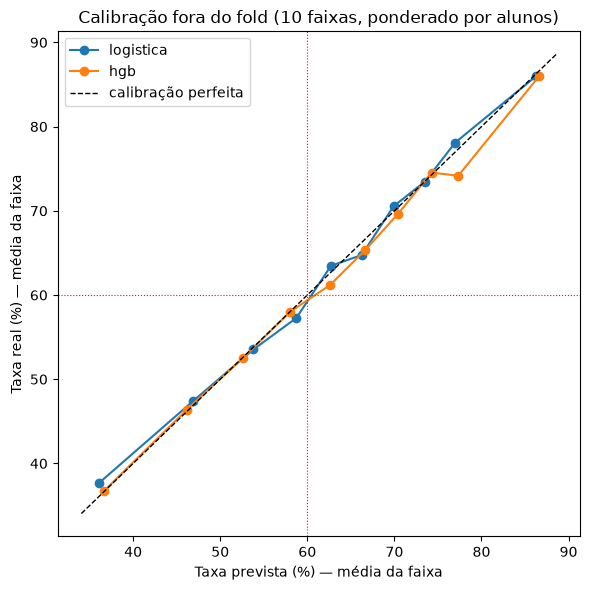

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt

from src.modeling.cv import previsoes_fora_do_fold

IMAGES = Path("images")

previsoes_oof = {
    nome: previsoes_fora_do_fold(construtores[nome], treino, features)
    for nome in ["logistica", "hgb"]
}


def tabela_calibracao(taxa_real: pd.Series, prob: pd.Series, n_alunos: pd.Series, n_faixas: int = 10) -> pd.DataFrame:
    dados = pd.DataFrame({
        "real": taxa_real.astype(float),
        "prevista": 100 * prob,
        "n": n_alunos.astype(float),
    })
    dados["faixa"] = pd.qcut(dados["prevista"], n_faixas, labels=False, duplicates="drop")
    return dados.groupby("faixa").apply(lambda g: pd.Series({
        "municipios": len(g),
        "alunos": g["n"].sum(),
        "prevista_media": np.average(g["prevista"], weights=g["n"]),
        "real_media": np.average(g["real"], weights=g["n"]),
    }))


tabelas_calibracao = {}
for nome, prob in previsoes_oof.items():
    tabela = tabela_calibracao(treino[config.COL_ALVO], prob, treino[config.COL_PESO])
    tabelas_calibracao[nome] = tabela
    erro_calibracao = np.average(
        (tabela["prevista_media"] - tabela["real_media"]).abs(), weights=tabela["alunos"]
    )
    print(f"=== {nome} | erro médio de calibração (ponderado): {erro_calibracao:.2f} p.p.")
    print(tabela.round(2).to_string())
    print()

fig, ax = plt.subplots(figsize=(6, 6))
for nome, tabela in tabelas_calibracao.items():
    ax.plot(tabela["prevista_media"], tabela["real_media"], marker="o", label=nome)
valores = pd.concat([t[["prevista_media", "real_media"]] for t in tabelas_calibracao.values()])
limites = [valores.min().min() - 2, valores.max().max() + 2]
ax.plot(limites, limites, "k--", lw=1, label="calibração perfeita")
ax.axhline(config.LIMIAR_RISCO, color="red", lw=0.8, ls=":")
ax.axvline(config.LIMIAR_RISCO, color="red", lw=0.8, ls=":")
ax.set_xlabel("Taxa prevista (%) — média da faixa")
ax.set_ylabel("Taxa real (%) — média da faixa")
ax.set_title("Calibração fora do fold (10 faixas, ponderado por alunos)")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "04_calibracao_oof.png", dpi=120, bbox_inches="tight")
plt.show()

### Conclusão da calibração

Erro médio de calibração fora do fold: 0,59 p.p. (HGB) e 0,82 p.p. (logística), sem padrão em "S" — as previsões acompanham a diagonal de 37% a 86%. Perto do limiar de 60%, a faixa prevista de ~58% acerta em cheio e a de ~62,6% é levemente otimista (real 61,2%): alguns municípios de fronteira podem estar ligeiramente abaixo do previsto. **Nenhuma recalibração aplicada** (ganho irrelevante frente à complexidade).

## 6. Avaliação final no teste

Modelos ajustados no treino completo (`python -m src.modeling.train`) e avaliados uma única vez nos municípios de teste, não usados em nenhuma decisão. A comparação com a média da validação cruzada mostra se a seleção inflou os resultados.

In [9]:
import json

relatorio_teste = json.loads(Path("reports/metricas_teste.json").read_text())
metricas_teste = relatorio_teste["metricas_teste"]

linhas = {}
for nome in ["logistica", "hgb"]:
    linhas[f"{nome} | CV (média)"] = resultados_modelos[nome].drop(columns="fold").mean()
    linhas[f"{nome} | teste"] = pd.Series(metricas_teste[nome])

comparacao_teste = pd.DataFrame(linhas).T
print(comparacao_teste.round(4).to_string())

                        auc_aluno  auc_teto  pct_teto  log_loss  mae_pp  auc_risco_municipio
logistica | CV (média)     0.6482    0.6828    0.8111    0.6450  7.0485               0.8710
logistica | teste          0.6522    0.6896    0.8026    0.6356  7.8342               0.8707
hgb | CV (média)           0.6498    0.6828    0.8196    0.6435  6.7455               0.8801
hgb | teste                0.6572    0.6896    0.8291    0.6320  6.9764               0.8737


### Conclusão da avaliação no teste

Métricas do HGB no teste dentro de ±1 desvio-padrão da média da validação cruzada (% do teto 82,9% vs. 82,0% ± 1,5; MAE 6,98 vs. 6,75 ± 0,58 p.p.; AUC de risco 0,874 vs. 0,880 ± 0,009): **a seleção de modelo não inflou os resultados** e o modelo generaliza para municípios não vistos. No teste, a vantagem do HGB sobre a logística aumenta (MAE 0,86 p.p. menor; +2,7 pontos de % do teto).

Resumo: o modelo captura ~83% do sinal alcançável com dados municipais, erra a taxa de alfabetização municipal em ~7 p.p. (baseline: 12,9) e identifica municípios abaixo de 60% com AUC de 0,87.